In [8]:
# ## 1. Datenbankverbindung testen

SyntaxError: invalid syntax (1461633863.py, line 2)

In [1]:
import psycopg

try:
    conn = psycopg.connect(
        dbname="f_jonas2",
        user="gisadmin",
        password="gisadmin",
        host="10.216.243.25",
        port=5432,
        sslmode="require"
    )
    print("Verbindung erfolgreich!")
    conn.close()
except Exception as e:
    print("Fehler bei der Verbindung:", e)


Verbindung erfolgreich!


In [ ]:
# ## 2. Redispatch-Daten laden
#
# Laden der EEG-Redispatch-Daten aus der Bayernwerk-Tabelle.


In [2]:
import psycopg
import pandas as pd

try:
    conn = psycopg.connect(
        dbname="f_jonas2",
        user="gisadmin",
        password="gisadmin",
        host="10.216.243.25",
        port=5432,
        sslmode="require"
    )
    query = "SELECT * FROM redispatch.redispatch_bayernwerk_final WHERE energie ='Solare Strahlungsenergie' LIMIT 1000;"
    df = pd.read_sql(query, conn)
    conn.close()
    print(f"✓ {len(df)} Datensätze geladen")
except Exception as e:
    print("Fehler bei der Abfrage:", e)
    df = pd.DataFrame()  # Leeres DataFrame, falls Fehler


C:\Users\user\AppData\Local\Temp\ipykernel_11824\573752661.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


✓ 1000 Datensätze geladen


In [ ]:
# ## 3. Geometrie-Daten vorbereiten
#
# Konvertierung der WKB-Geometrie in GeoDataFrame für räumliche Operationen.


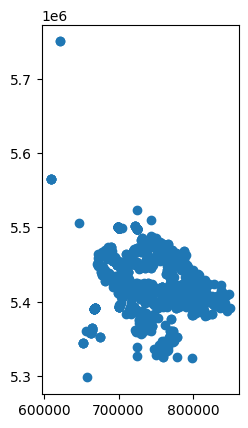

In [3]:
import geopandas as gpd
from shapely import wkb

if not df.empty and 'geom' in df.columns:
    df['geom'] = df['geom'].apply(lambda x: wkb.loads(x, hex=True) if isinstance(x, str) else None)
    gdf = gpd.GeoDataFrame(df, geometry='geom', crs='EPSG:25832')
    gdf.plot()
else:
    print("Keine Geometriedaten vorhanden!")


In [ ]:
# ## 4. Beispiel-Datenpunkt auswählen und Koordinaten transformieren
#
# Wir nehmen den ersten Datenpunkt als Beispiel und transformieren die Koordinaten
# von EPSG:25832 (UTM Zone 32N) nach EPSG:4326 (WGS84).


In [4]:
from wetterdienst.provider.dwd.observation import DwdObservationRequest

# Beispiel: Ersten Datenpunkt aus df nehmen
row = df.iloc[50]
startpunkt = row['star']
endpunkt = row['ende']
dauer = row['duration']

# Endpunkt um 10 Minuten erhöhen, damit der Zeitraum vollständig abgedeckt ist
endpunkt = pd.to_datetime(endpunkt) + pd.Timedelta(minutes=10)

geom = row['geom']  # shapely Point

# Geometrie in GeoDataFrame umwandeln und transformieren
single_gdf = gpd.GeoDataFrame([[geom]], columns=["geometry"], crs="EPSG:25832")
single_gdf = single_gdf.to_crs("EPSG:4326")
geom_wgs84 = single_gdf.iloc[0].geometry

# Richtige Reihenfolge: (lat, lon) = (y, x)
lat, lon = geom_wgs84.y, geom_wgs84.x

print(f"Datenpunkt-Koordinaten:")
print(f"  Latitude:  {lat:.6f}°")
print(f"  Longitude: {lon:.6f}°")
print(f"  Zeitraum:  {startpunkt} bis {endpunkt}")
print(f"  Dauer:  {dauer}")


Datenpunkt-Koordinaten:
  Latitude:  49.592577°
  Longitude: 12.107263°
  Zeitraum:  2025-01-13 12:01:25 bis 2025-01-13 15:46:38
  Dauer:  216.0


In [5]:
request = DwdObservationRequest(
    parameters=("10_minutes", "wind", "wind_speed"),
    start_date=startpunkt,
    end_date=endpunkt,
)
values = request.interpolate(latlon=(lat, lon))
wetter_df = values.df
display(wetter_df)


Interpolation might be slow for high resolutions due to mass of data


KeyboardInterrupt: 

In [ ]:
# ## 5. Verfügbare Wetterstationen abrufen
#
# Abruf aller DWD-Stationen, die 10-Minuten-Windgeschwindigkeitsdaten bereitstellen.


In [6]:
from wetterdienst.provider.dwd.observation import DwdObservationRequest
from wetterdienst import Settings
import polars as pl

# Request für 10-Minuten-Windgeschwindigkeit
settings = Settings(
    ts_shape="long",
    ts_humanize=True,
    ts_convert_units=True
)

# Zeitraum für die Stationsabfrage
start_date = "2025-01-01"
end_date   = "2025-12-31"

# Anfrage für 10-Minuten-Windgeschwindigkeit (wind_speed = ff_10)
request = DwdObservationRequest(
    parameters=[("10_minutes", "wind", "wind_speed")],
    start_date=start_date,
    end_date=end_date,
    settings=settings
)

# Alle Stationen (Metadaten) für diesen Parameter holen
req_stations = request.all()
stations = req_stations.df  # Polars-DataFrame

print(f"✓ {len(stations)} Wetterstationen gefunden")


✓ 310 Wetterstationen gefunden


In [ ]:
# ## 6. Die 4 nächsten Wetterstationen identifizieren
#
# Berechnung der Distanz zwischen dem Datenpunkt und allen Wetterstationen,
# dann Auswahl der 4 nächstgelegenen Stationen.


In [7]:
from shapely.geometry import Point

# Konvertiere zu pandas und erstelle GeoDataFrame
stations_pd = stations.to_pandas()
stations_gdf = gpd.GeoDataFrame(
    stations_pd,
    geometry=gpd.points_from_xy(stations_pd['longitude'], stations_pd['latitude']),
    crs="EPSG:4326"
)

# Datenpunkt als Shapely-Objekt
my_point = Point(lon, lat)

# Für Distanzberechnung: beide in projiziertes CRS (z.B. EPSG:25832)
stations_gdf_proj = stations_gdf.to_crs("EPSG:25832")
my_point_proj = gpd.GeoSeries([my_point], crs="EPSG:4326").to_crs("EPSG:25832").iloc[0]

# Distanz berechnen (in Metern)
stations_gdf_proj['distance'] = stations_gdf_proj.geometry.distance(my_point_proj)

# Nach Distanz sortieren und die vier nächsten auswählen
nearest_stations = stations_gdf_proj.nsmallest(4, 'distance')

print("Die 4 nächsten Wetterstationen:")
print(nearest_stations[['station_id', 'name', 'state', 'distance']].to_string(index=False))
display(nearest_stations)


Die 4 nächsten Wetterstationen:
station_id                              name  state     distance
     05397                            Weiden Bayern  9907.233301
     01357 Fichtelberg/Oberfranken-Hüttstadl Bayern 47343.253227
     07370                       Waldmünchen Bayern 47421.859314
     07394              Wunsiedel-Schönbrunn Bayern 49755.123078


,resolution,dataset,station_id,start_date,end_date,latitude,longitude,height,name,state,geometry,distance
207,10_minutes,wind,05397,1991-07-04 00:00:00+00:00,2026-01-17 00:00:00+00:00,49.6662,12.1844,440.0,Weiden,Bayern,POINT (729773.734 5506388.043),9907.233301
54,10_minutes,wind,01357,1993-12-15 00:00:00+00:00,2026-01-17 00:00:00+00:00,49.9807,11.8376,655.0,Fichtelberg/Oberfranken-Hüttstadl,Bayern,POINT (703429.569 5540344.128),47343.253227
261,10_minutes,wind,07370,2006-07-27 00:00:00+00:00,2026-01-17 00:00:00+00:00,49.3910,12.6838,499.0,Waldmünchen,Bayern,POINT (767298.993 5477450.526),47421.859314
267,10_minutes,wind,07394,2006-06-01 00:00:00+00:00,2026-01-17 00:00:00+00:00,50.0315,11.9745,622.0,Wunsiedel-Schönbrunn,Bayern,POINT (713017.747 5546372.483),49755.123078


In [ ]:
# ## 7. Visualisierung der ausgewählten Stationen
#
# Kartendarstellung: Alle Stationen (grau), die 4 nächsten Stationen (blau)
# und der Datenpunkt (roter Stern).


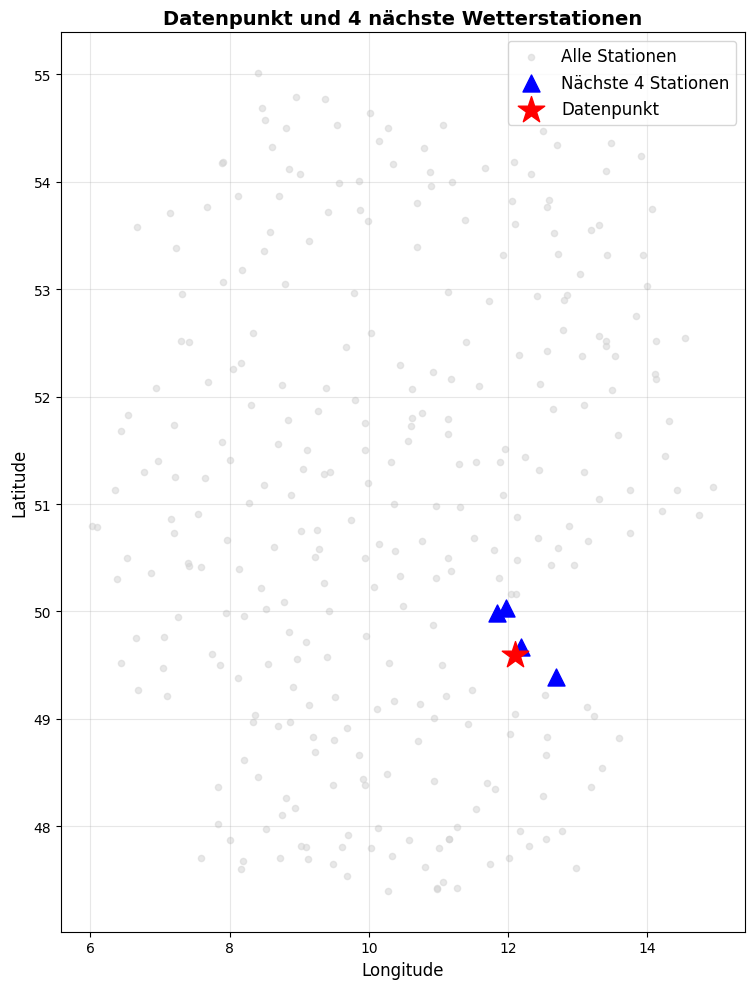

In [8]:
import matplotlib.pyplot as plt

# GeoDataFrame für den Datenpunkt erstellen
datenpunkt_gdf = gpd.GeoDataFrame(
    [{'geometry': my_point}],
    crs="EPSG:4326"
)

# nearest_stations zurück nach EPSG:4326 transformieren
nearest_stations_wgs84 = nearest_stations.to_crs("EPSG:4326")

# Plot
fig, ax = plt.subplots(figsize=(10, 10))
stations_gdf.plot(ax=ax, color='lightgray', alpha=0.5, markersize=20, label='Alle Stationen')
nearest_stations_wgs84.plot(ax=ax, color='blue', marker='^', markersize=150, label='Nächste 4 Stationen', zorder=5)
datenpunkt_gdf.plot(ax=ax, color='red', marker='*', markersize=400, label='Datenpunkt', zorder=10)

plt.legend(fontsize=12)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.title('Datenpunkt und 4 nächste Wetterstationen', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# ## 8. Wetterdaten für die ausgewählten Stationen abrufen
#
# Abruf der 10-Minuten-Windgeschwindigkeitsdaten für die 4 nächsten Stationen
# im Zeitraum des Datenpunkts.


In [9]:
import pandas as pd
from wetterdienst.provider.dwd.observation import DwdObservationRequest

# Zeitraum vom Datenpunkt
start_date = startpunkt
end_date = endpunkt

# Stations-IDs der vier nächsten Stationen
station_ids = nearest_stations['station_id'].tolist()

print(f"Ausgewählte Stationen: {station_ids}")
print(f"Zeitraum: {start_date} bis {end_date}")
print("\n" + "="*60)

# Ergebnisse sammeln
all_data = []

for station_id in station_ids:
    print(f"\nVerarbeite Station {station_id}...")
    request = DwdObservationRequest(
        parameters=[("10_minutes", "wind", "wind_speed")],
        start_date=start_date,
        end_date=end_date
    )
    stations = request.filter_by_station_id(station_id=(station_id,))

    # Für jede Station alle Ergebnisse robust per .values.query() holen
    station_data_found = False
    for result in stations.values.query():
        df_station = result.df.drop_nulls()
        if len(df_station) > 0:
            df_station = df_station.with_columns(pl.lit(station_id).alias("station_id"))
            all_data.append(df_station)
            print(f"  ✓ {len(df_station)} Datenpunkte gefunden")
            station_data_found = True
        else:
            print(f"  ⚠ Keine Daten nach drop_nulls()")

    if not station_data_found:
        print(f"  ⚠️ KEINE Daten im angegebenen Zeitraum!")

print("\n" + "="*60)

# Alle Daten zusammenführen
if all_data:
    result_df = pl.concat(all_data)
    unique_stations = result_df['station_id'].n_unique()
    print(f"\n✓ Insgesamt {len(result_df)} Datenpunkte von {unique_stations} Stationen")
else:
    result_df = None
    print("\n⚠️ KEINE Daten gefunden!")

display(result_df)


Ausgewählte Stationen: ['05397', '01357', '07370', '07394']
Zeitraum: 2025-01-13 12:01:25 bis 2025-01-13 15:46:38


Verarbeite Station 05397...
  ✓ 22 Datenpunkte gefunden

Verarbeite Station 01357...
  ✓ 22 Datenpunkte gefunden

Verarbeite Station 07370...
  ✓ 22 Datenpunkte gefunden

Verarbeite Station 07394...
  ✓ 22 Datenpunkte gefunden


✓ Insgesamt 88 Datenpunkte von 4 Stationen


station_id,resolution,dataset,parameter,date,value,quality
str,str,str,str,"datetime[μs, UTC]",f64,f64
"""05397""","""10_minutes""","""wind""","""wind_speed""",2025-01-13 12:10:00 UTC,1.7,3.0
"""05397""","""10_minutes""","""wind""","""wind_speed""",2025-01-13 12:20:00 UTC,2.5,3.0
"""05397""","""10_minutes""","""wind""","""wind_speed""",2025-01-13 12:30:00 UTC,2.4,3.0
"""05397""","""10_minutes""","""wind""","""wind_speed""",2025-01-13 12:40:00 UTC,2.7,3.0
"""05397""","""10_minutes""","""wind""","""wind_speed""",2025-01-13 12:50:00 UTC,2.3,3.0
…,…,…,…,…,…,…
"""07394""","""10_minutes""","""wind""","""wind_speed""",2025-01-13 15:00:00 UTC,2.4,3.0
"""07394""","""10_minutes""","""wind""","""wind_speed""",2025-01-13 15:10:00 UTC,2.0,3.0
"""07394""","""10_minutes""","""wind""","""wind_speed""",2025-01-13 15:20:00 UTC,1.8,3.0


In [ ]:
# ## 9. Inverse Distance Weighting (IDW) Interpolation
#
# Die Windgeschwindigkeit am Datenpunkt wird mittels IDW berechnet:
#
# $$\text{interpolierter\_wert} = \frac{\sum_{i=1}^{n} \frac{w_i}{d_i^p}}{\sum_{i=1}^{n} \frac{1}{d_i^p}}$$
#
# wobei:
# - $w_i$ = Windgeschwindigkeit an Station $i$
# - $d_i$ = Distanz zur Station $i$
# - $p$ = Power-Parameter (typisch: 2 für inverse quadratische Distanz)


In [11]:
import numpy as np

# Konvertiere result_df zu pandas für einfachere Bearbeitung
result_pd = result_df.to_pandas()

# Mergen mit nearest_stations um die Distanzen zu haben
result_pd['station_id'] = result_pd['station_id'].astype(str)
nearest_stations['station_id'] = nearest_stations['station_id'].astype(str)

# Merge mit den Distanzen
result_with_dist = result_pd.merge(
    nearest_stations[['station_id', 'distance', 'latitude', 'longitude']],
    on='station_id',
    how='left'
)


def calculate_interpolation(group, power=2):
    """
    Berechne IDW und sammle alle relevanten Informationen
    """
    weights = 1.0 / (group['distance'].values ** power + 1e-10)
    interpolated_value = np.sum(group['value'].values * weights) / np.sum(weights)

    first_row = group.iloc[0]
    station_list = sorted(group['station_id'].tolist())

    return pd.Series({
        'parameter': first_row['parameter'],
        'dataset': first_row['dataset'],
        'parameter_name': first_row['parameter'],
        'value': interpolated_value,
        'latitude': round(lat, 6),
        'longitude': round(lon, 6),
        'station_ids': station_list
    })

# Gruppiere nach Zeitstempel und interpoliere (FutureWarning vermeiden)
cols_to_use = [c for c in result_with_dist.columns if c != 'date']
interpolated_wind = result_with_dist.groupby('date', group_keys=False)[cols_to_use].apply(
    lambda x: calculate_interpolation(x, power=2)
).reset_index()

# Spaltenreihenfolge und -namen wie gewünscht setzen
interpolated_wind = interpolated_wind.rename(columns={
    'date': 'date',
    'parameter': 'parameter',
    'dataset': 'dataset',
    'parameter_name': 'parameter_name',
    'value': 'value',
    'latitude': 'latitude',
    'longitude': 'longitude',
    'station_ids': 'station_ids'
})
interpolated_wind = interpolated_wind[['date', 'parameter', 'dataset', 'parameter_name', 'value', 'latitude', 'longitude', 'station_ids']]

# station_ids als String-Liste speichern
interpolated_wind['station_ids'] = interpolated_wind['station_ids'].apply(lambda x: str(x))

# result_df = interpolated_wind (wie gewünscht)
result_df = interpolated_wind.copy()

print(f"✓ {len(result_df)} Zeitpunkte interpoliert und gespeichert")
display(result_df)


✓ 22 Zeitpunkte interpoliert und gespeichert


,date,parameter,dataset,parameter_name,value,latitude,longitude,station_ids
0,2025-01-13 12:10:00+00:00,wind_speed,wind,wind_speed,1.791166,49.592577,12.107263,"['01357', '05397', '07370', '07394']"
1,2025-01-13 12:20:00+00:00,wind_speed,wind,wind_speed,2.555215,49.592577,12.107263,"['01357', '05397', '07370', '07394']"
2,2025-01-13 12:30:00+00:00,wind_speed,wind,wind_speed,2.454924,49.592577,12.107263,"['01357', '05397', '07370', '07394']"
3,2025-01-13 12:40:00+00:00,wind_speed,wind,wind_speed,2.724615,49.592577,12.107263,"['01357', '05397', '07370', '07394']"
4,2025-01-13 12:50:00+00:00,wind_speed,wind,wind_speed,2.286283,49.592577,12.107263,"['01357', '05397', '07370', '07394']"
5,2025-01-13 13:00:00+00:00,wind_speed,wind,wind_speed,1.784195,49.592577,12.107263,"['01357', '05397', '07370', '07394']"
6,2025-01-13 13:10:00+00:00,wind_speed,wind,wind_speed,2.308719,49.592577,12.107263,"['01357', '05397', '07370', '07394']"
7,2025-01-13 13:20:00+00:00,wind_speed,wind,wind_speed,1.662366,49.592577,12.107263,"['01357', '05397', '07370', '07394']"
8,2025-01-13 13:30:00+00:00,wind_speed,wind,wind_speed,1.986967,49.592577,12.107263,"['01357', '05397', '07370', '07394']"
9,2025-01-13 13:40:00+00:00,wind_speed,wind,wind_speed,1.685208,49.592577,12.107263,"['01357', '05397', '07370', '07394']"


In [ ]:
# ## 10. Visualisierung der interpolierten Zeitreihe
#
# Vergleich der interpolierten Windgeschwindigkeit (rot) mit den Originaldaten
# der einzelnen Stationen (halbtransparent).


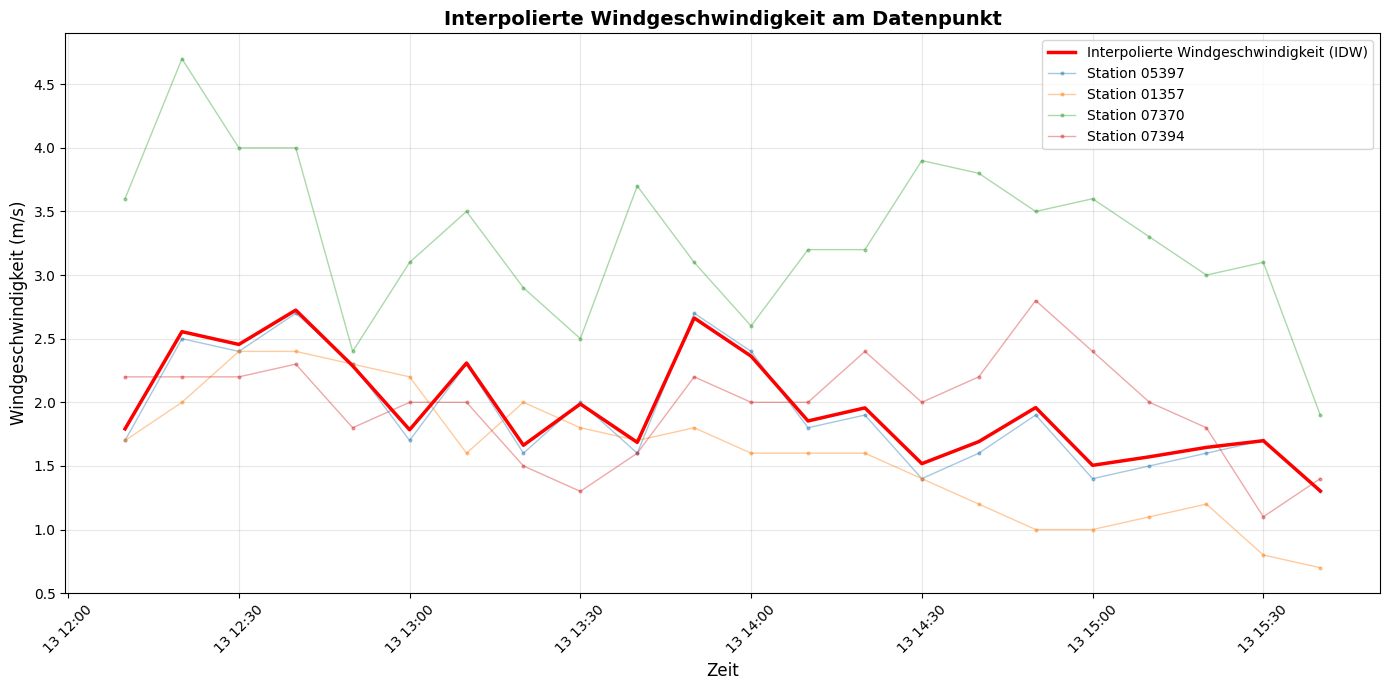

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 7))

# Interpolierte Werte plotten
ax.plot(interpolated_wind['date'], interpolated_wind['value'],
        'r-', linewidth=2.5, label='Interpolierte Windgeschwindigkeit (IDW)', zorder=10)

# Originaldaten der einzelnen Stationen als Referenz
n = len(result_pd['station_id'].unique())
colors = plt.get_cmap("tab10")(range(n))
for idx, station_id in enumerate(result_pd['station_id'].unique()):
    station_data = result_pd[result_pd['station_id'] == station_id]
    ax.plot(station_data['date'], station_data['value'],
            'o-', alpha=0.4, markersize=2, linewidth=1,
            color=colors[idx % len(colors)], label=f'Station {station_id}')

ax.set_xlabel('Zeit', fontsize=12)
ax.set_ylabel('Windgeschwindigkeit (m/s)', fontsize=12)
ax.set_title('Interpolierte Windgeschwindigkeit am Datenpunkt', fontsize=14, fontweight='bold')
ax.legend(loc='best', fontsize=10)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [67]:
# result_table_wind

,eventnummer,date,dataset,parameter,wind_speed,latitude,longitude,station_ids
0,2563,2025-01-30 14:10:00+00:00,wind,wind_speed,1.330356,49.010715,12.495517,"['04911', '04104', '13676', '07395']"
1,2570,2025-01-30 14:10:00+00:00,wind,wind_speed,1.492551,49.496347,12.094236,"['05397', '07370', '04104', '03534']"
2,2678,2025-01-30 13:10:00+00:00,wind,wind_speed,1.106699,49.010715,12.495517,"['04911', '04104', '13676', '07395']"
3,2678,2025-01-30 13:20:00+00:00,wind,wind_speed,0.927436,49.010715,12.495517,"['04911', '04104', '13676', '07395']"
4,2678,2025-01-30 13:30:00+00:00,wind,wind_speed,1.166477,49.010715,12.495517,"['04911', '04104', '13676', '07395']"
...,...,...,...,...,...,...,...,...
1993,99838,2025-03-20 15:50:00+00:00,wind,wind_speed,2.328434,48.646210,12.125670,"['13676', '07395', '04911', '01262']"
1994,99838,2025-03-20 16:00:00+00:00,wind,wind_speed,2.190023,48.646210,12.125670,"['13676', '07395', '04911', '01262']"
1995,99838,2025-03-20 16:10:00+00:00,wind,wind_speed,2.012962,48.646210,12.125670,"['13676', '07395', '04911', '01262']"
1996,99838,2025-03-20 16:20:00+00:00,wind,wind_speed,1.685071,48.646210,12.125670,"['13676', '07395', '04911', '01262']"


In [63]:
# ## 11. Statistik der interpolierten Werte
import psycopg
import pandas as pd
import geopandas as gpd
from shapely import wkb
from wetterdienst.provider.dwd.observation import DwdObservationRequest
import numpy as np

# 1. Redispatch-Daten laden (nur 100 Einträge für Test)
conn = psycopg.connect(
    dbname="f_jonas2",
    user="gisadmin",
    password="gisadmin",
    host="10.216.243.25",
    port=5432,
    sslmode="require"
)
query = "SELECT eventnummer, star, ende, geom FROM redispatch.redispatch_bayernwerk_final WHERE energie = 'Solare Strahlungsenergie' LIMIT 100"
df = pd.read_sql(query, conn)
conn.close()

# 2. Geometrie konvertieren
df['geom'] = df['geom'].apply(lambda x: wkb.loads(x, hex=True) if isinstance(x, str) else None)
gdf = gpd.GeoDataFrame(df, geometry='geom', crs='EPSG:25832')
gdf = gdf.to_crs("EPSG:4326")

# Verbindung für den Schreibzugriff herstellen
write_conn = psycopg.connect(
    dbname="f_jonas2",
    user="gisadmin",
    password="gisadmin",
    host="10.216.243.25",
    port=5432,
    sslmode="require"
)
write_cursor = write_conn.cursor()

# Tabelle erstellen (falls nicht vorhanden)
write_cursor.execute("""
    CREATE TABLE IF NOT EXISTS redispatch.solar_interpolated (
        eventnummer TEXT,
        date TIMESTAMP,
        dataset TEXT,
        parameter TEXT,
        global_radiation FLOAT,
        latitude FLOAT,
        longitude FLOAT,
        station_ids TEXT,
        PRIMARY KEY (eventnummer, date)
    )
""")
write_conn.commit()

for idx, row in gdf.iterrows():
    eventnummer = row['eventnummer']
    startpunkt = row['star']
    endpunkt = pd.to_datetime(row['ende']) + pd.Timedelta(minutes=10)
    geom = row['geom']
    lat, lon = geom.y, geom.x

    # Wetterstationen abrufen
    settings = Settings(ts_shape="long", ts_humanize=True, ts_convert_units=True)
    request = DwdObservationRequest(
        parameters=[("10_minutes", "solar", "radiation_global")],
        start_date=startpunkt,
        end_date=endpunkt,
        settings=settings
    )
    req_stations = request.all()
    stations = req_stations.df.to_pandas()
    stations_gdf = gpd.GeoDataFrame(
        stations,
        geometry=gpd.points_from_xy(stations['longitude'], stations['latitude']),
        crs="EPSG:4326"
    )
    my_point = Point(lon, lat)
    # Für Distanzberechnung: beide in projiziertes CRS (z.B. EPSG:25832)
    stations_gdf_proj = stations_gdf.to_crs("EPSG:25832")
    my_point_proj = gpd.GeoSeries([my_point], crs="EPSG:4326").to_crs("EPSG:25832").iloc[0]
    stations_gdf_proj['distance'] = stations_gdf_proj.geometry.distance(my_point_proj)
    nearest_stations = stations_gdf_proj.nsmallest(4, 'distance')
    station_ids = nearest_stations['station_id'].astype(str).tolist()

    # Wetterdaten für die 4 nächsten Stationen abrufen
    all_data = []
    for station_id in station_ids:
        req = DwdObservationRequest(
            parameters=[("10_minutes", "solar", "radiation_global")],
            start_date=startpunkt,
            end_date=endpunkt
        )
        stations_filtered = req.filter_by_station_id(station_id=(station_id,))
        for result in stations_filtered.values.query():
            df_station = result.df.drop_nulls()
            if len(df_station) > 0:
                df_station = df_station.with_columns(pl.lit(station_id).alias("station_id"))
                all_data.append(df_station)
    if all_data:
        import polars as pl
        result_df = pl.concat(all_data)
        result_pd = result_df.to_pandas()
        nearest_stations['station_id'] = nearest_stations['station_id'].astype(str)
        result_pd['station_id'] = result_pd['station_id'].astype(str)
        result_with_dist = result_pd.merge(
            nearest_stations[['station_id', 'distance', 'latitude', 'longitude']],
            on='station_id', how='left'
        )
        # IDW Interpolation für jeden Zeitstempel
        def calculate_interpolation(group, power=2):
            weights = 1.0 / (group['distance'].values ** power + 1e-10)
            interpolated_value = np.sum(group['value'].values * weights) / np.sum(weights)
            first_row = group.iloc[0]
            return pd.Series({
                'eventnummer': eventnummer,
                'dataset': first_row['dataset'] if 'dataset' in group else None,
                'parameter': first_row['parameter'] if 'parameter' in group else None,
                'global_radiation': interpolated_value,
                'latitude': round(lat, 6),
                'longitude': round(lon, 6),
                'station_ids': str(station_ids)
            })
        cols_to_use = [c for c in result_with_dist.columns if c != 'date']
        interpolated = result_with_dist.groupby('date', group_keys=False)[cols_to_use].apply(lambda x: calculate_interpolation(x, power=2)).reset_index()

        if not interpolated.empty:
            cols = ['eventnummer', 'date', 'dataset', 'parameter', 'global_radiation', 'latitude', 'longitude', 'station_ids']
            interpolated = interpolated.where(pd.notnull(interpolated), None)
            data_to_insert = interpolated[cols].values.tolist()

            write_cursor.executemany("""
                INSERT INTO redispatch.solar_interpolated
                (eventnummer, date, dataset, parameter, global_radiation, latitude, longitude, station_ids)
                VALUES (%s, %s, %s, %s, %s, %s, %s, %s)
                ON CONFLICT (eventnummer, date) DO UPDATE SET
                    dataset = EXCLUDED.dataset,
                    parameter = EXCLUDED.parameter,
                    global_radiation = EXCLUDED.global_radiation,
                    latitude = EXCLUDED.latitude,
                    longitude = EXCLUDED.longitude,
                    station_ids = EXCLUDED.station_ids
            """, data_to_insert)
            write_conn.commit()
            print(f"Event {eventnummer}: {len(data_to_insert)} Zeilen geschrieben.")

# Verbindung schließen
write_conn.close()
print("Solar-Daten in DB gespeichert.")



C:\Users\user\AppData\Local\Temp\ipykernel_14168\2710307539.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)
C:\Users\user\AppData\Local\Temp\ipykernel_14168\2710307539.py:98: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  interpolated = result_with_dist.groupby('date', group_keys=False).apply(lambda x: calculate_interpolation(x, power=2)).reset_index(drop=True)
C:\Users\user\AppData\Local\Temp\ipykernel_14168\2710307539.py:98: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is

In [64]:
# result_table_solar


,eventnummer,date,dataset,parameter,global_radiation,latitude,longitude,station_ids
0,1,2025-01-01 14:10:00+00:00,solar,radiation_global,11.319564,48.393480,11.217104,"['00232', '03379', '05404', '01262']"
1,2,2025-01-01 14:10:00+00:00,solar,radiation_global,11.306454,48.412410,11.224750,"['00232', '05404', '03379', '01262']"
2,6,2025-01-01 14:10:00+00:00,solar,radiation_global,11.365740,48.389389,11.195795,"['00232', '03379', '05404', '01262']"
3,8,2025-01-01 14:10:00+00:00,solar,radiation_global,11.343058,48.357678,11.198720,"['00232', '03379', '05404', '01262']"
4,10,2025-01-01 12:10:00+00:00,solar,radiation_global,20.996046,48.393480,11.217104,"['00232', '03379', '05404', '01262']"
...,...,...,...,...,...,...,...,...
3993,546,2025-01-16 09:40:00+00:00,solar,radiation_global,4.000000,49.609950,11.776260,"['05397', '01357', '03534', '07394']"
3994,546,2025-01-16 09:50:00+00:00,solar,radiation_global,4.000000,49.609950,11.776260,"['05397', '01357', '03534', '07394']"
3995,546,2025-01-16 10:00:00+00:00,solar,radiation_global,4.700000,49.609950,11.776260,"['05397', '01357', '03534', '07394']"
3996,546,2025-01-16 10:10:00+00:00,solar,radiation_global,4.700000,49.609950,11.776260,"['05397', '01357', '03534', '07394']"
